# Non-stationary kernels with Hexagonal SSPs (2D)

This notebook builds a **non-stationary** kernel out of **Hexagonal Spatial Semantic Pointers**
(SSPs, a.k.a. fractional power / Random Fourier encodings) in **2D**.

It is the 2D, hexagonal counterpart of `Nonstationary Kernels with SSPs.ipynb`.
Instead of masking arbitrary Fourier components, we exploit the *structure* of the hexagonal
encoding matrix $A$: its rows are organized into **grids**, one grid per (scale, rotation) pair,
with `domain_dim + 1` rows each. We modulate $A$ in a **block format** so that every row belonging
to a grid of the **same scale** is modulated the same way.

**Encoding.** A Hex-SSP maps $x\in\mathbb{R}^2$ to

$$\phi(x) = \mathcal{F}^{-1}\!\big[\exp(i\,A x)\big]\in\mathbb{R}^{d},$$

where $A$ is the `(ssp_dim, 2)` phase matrix. The kernel $k(x,x')=\phi(x)\cdot\phi(x')$ is
*stationary* (depends only on $x-x'$).

**Modulation.** Insert a per-frequency gain $g$ (a diagonal in the Fourier domain):

$$\tilde\phi(x) = \mathcal{F}^{-1}\!\big[\,g\odot\exp(i\,A x)\big].$$

If $g$ is constant we just reshape the (still stationary) kernel. If $g$ depends on **location**,
the kernel becomes non-stationary:

$$\tilde k(x,x') = \tfrac1d\sum_k g_k(x)\,g_k(x')\,e^{\,iA_k(x'-x)}.$$

We keep $g$ **block-constant across scales** and conjugate-symmetric (so $\tilde\phi$ stays real).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from ssp_bayes_opt import sspspace

/Users/nicoledumont/miniconda3/envs/mcbo/lib/python3.10/site-packages/nengo_loihi/version.py:20: UserWarning: This version of `nengo_loihi` has not been tested with your `nengo` version (4.0.0). The latest fully supported version is 3.2.0
  warnings.warn(


## 1. Build a 2D Hexagonal SSP space

A `HexagonalSSPSpace` builds its phase matrix from:

- `n_scales` spatial-frequency bands (grid **scales**),
- `n_rotates` grid **orientations**,
- the `domain_dim + 1 = 3` vertices of a 2-simplex (one grid = 3 rows).

The rows of the phase matrix are ordered `[rotation, scale, simplex-vertex]`, then made
conjugate-symmetric. So the positive-frequency block has
`d = n_scales * n_rotates * 3` rows, and `ssp_dim = 2*d + 1`.

In [2]:
domain_bounds = np.array([[-5, 5], [-5, 5]])

n_scales  = 8              # number of grid scales (spatial-frequency bands)
n_rotates = 6              # number of grid orientations
scale_min, scale_max = 0.1, np.pi

ssp_space = sspspace.HexagonalSSPSpace(
    domain_dim=2,
    n_scales=n_scales,
    n_rotates=n_rotates,
    scale_min=scale_min,
    scale_max=scale_max,
    domain_bounds=domain_bounds,
    length_scale=1.0,
)

A       = ssp_space.phase_matrix                                 # (ssp_dim, 2) encoding matrix
d_pos   = ssp_space.num_grids * ssp_space.grid_basis_dim         # number of positive-frequency rows

print(f'ssp_dim            = {ssp_space.ssp_dim}')
print(f'phase matrix A     = {A.shape}')
print(f'num grids          = {ssp_space.num_grids}   (= n_scales * n_rotates)')
print(f'rows per grid      = {ssp_space.grid_basis_dim}   (= domain_dim + 1 simplex vertices)')
print(f'positive freqs  d  = {d_pos}   ->  ssp_dim = 2*d + 1 = {2*d_pos + 1}')

ssp_dim            = 289
phase matrix A     = (289, 2)
num grids          = 48   (= n_scales * n_rotates)
rows per grid      = 3   (= domain_dim + 1 simplex vertices)
positive freqs  d  = 144   ->  ssp_dim = 2*d + 1 = 289


## 2. The stationary Hex-SSP kernel

With no modulation the kernel $k(x,x')=\phi(x)\cdot\phi(x')$ is stationary: the similarity map to
any query point is the same hexagonally-symmetric bump, just translated. We build a grid over the
domain once and reuse it throughout.

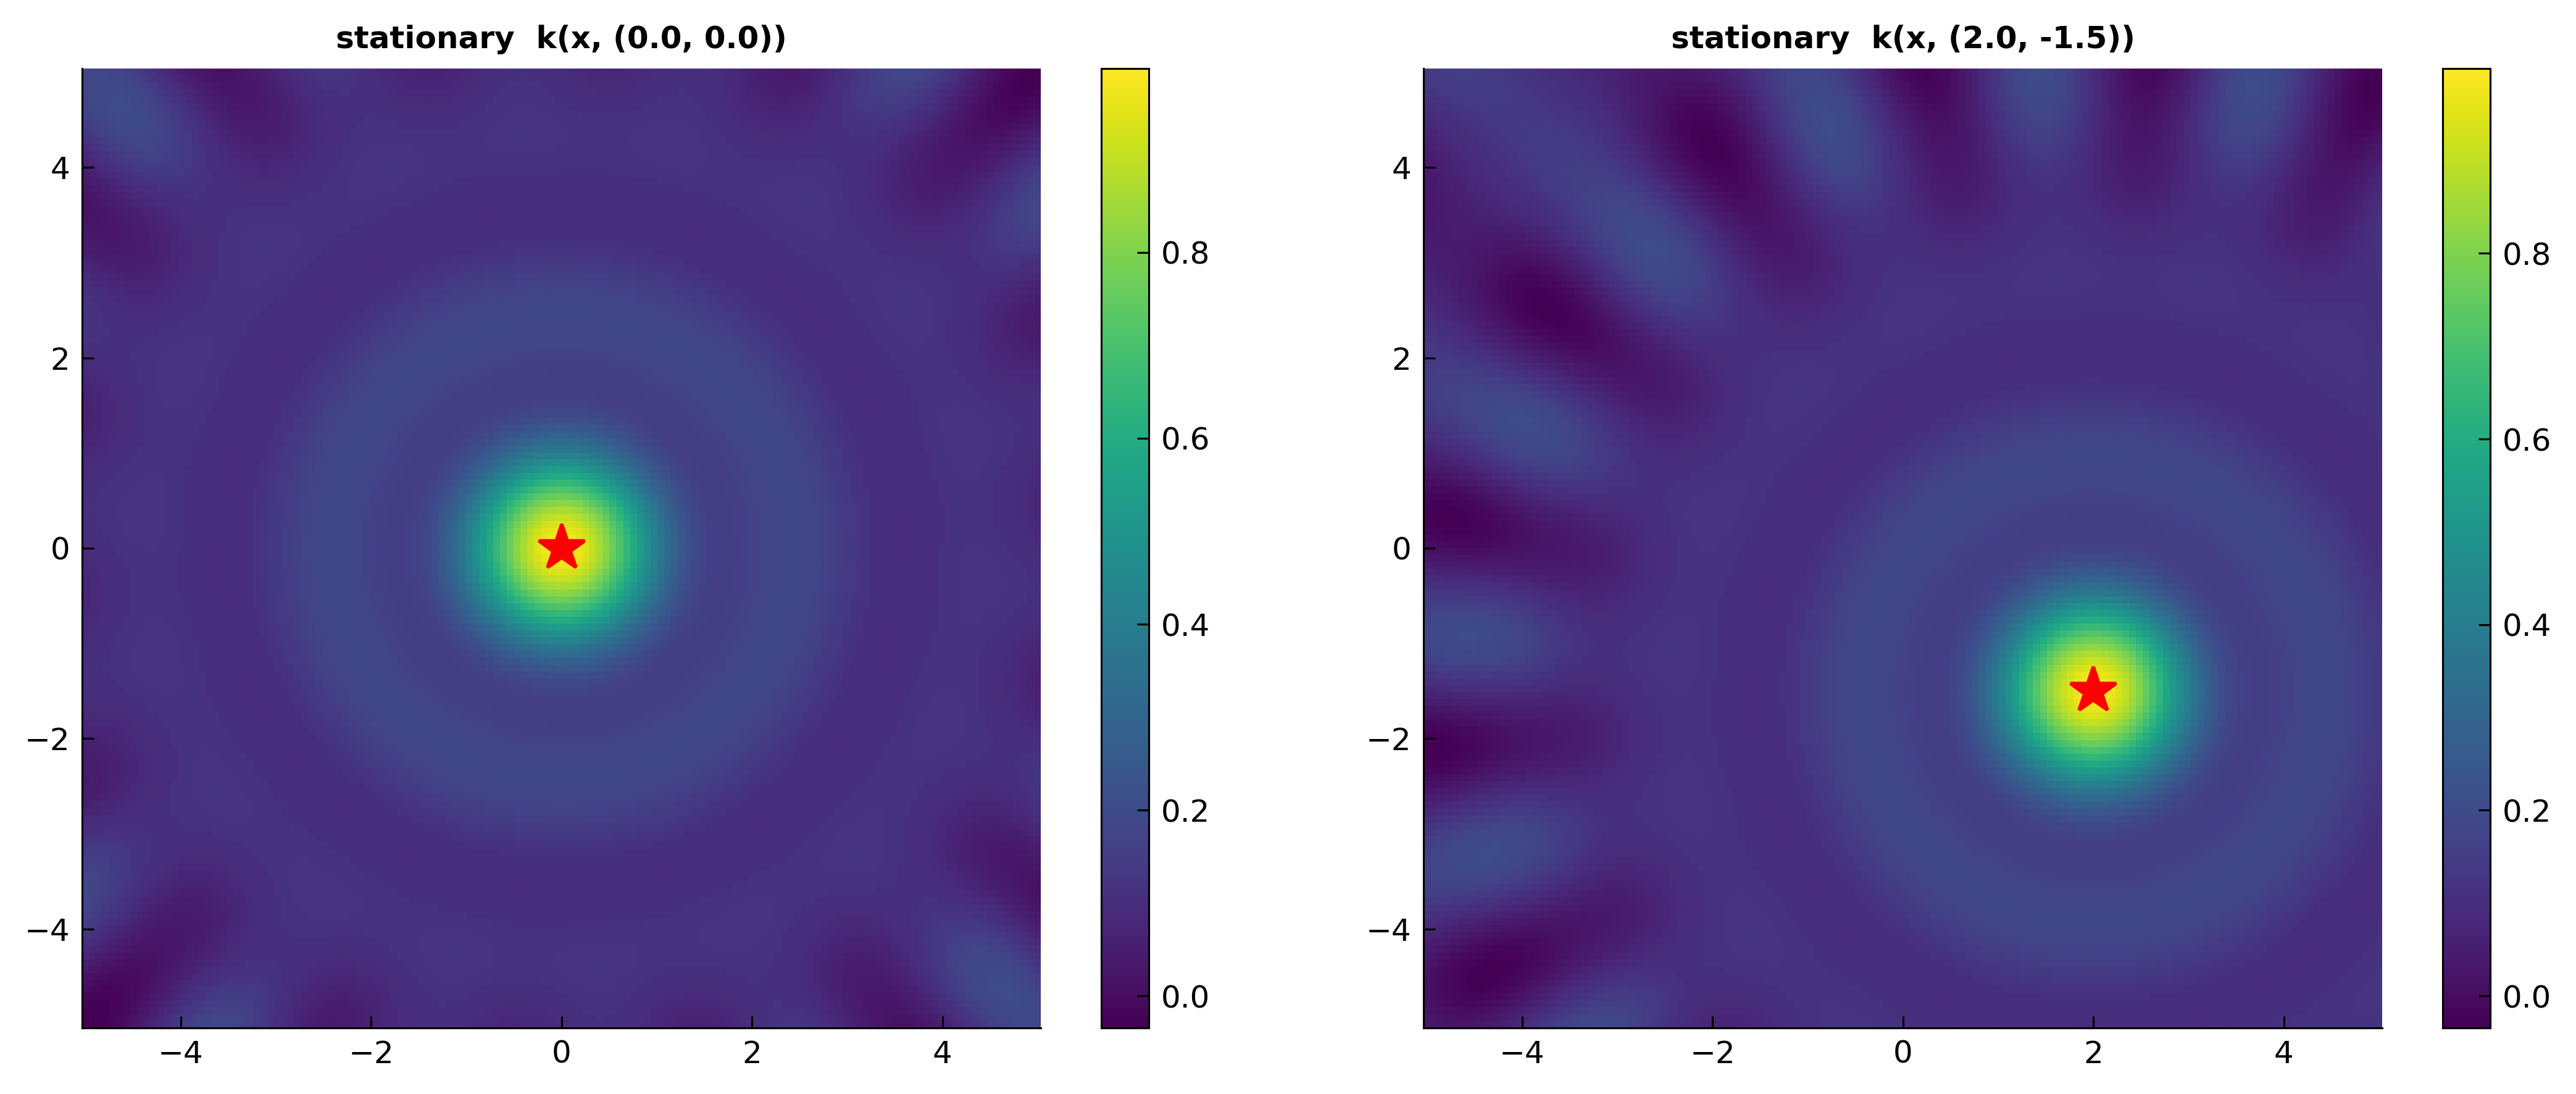

In [3]:
n_grid = 140
xs = np.linspace(domain_bounds[0, 0], domain_bounds[0, 1], n_grid)
ys = np.linspace(domain_bounds[1, 0], domain_bounds[1, 1], n_grid)
X, Y = np.meshgrid(xs, ys)
grid_pts = np.vstack([X.ravel(), Y.ravel()]).T          # (n_grid**2, 2)

ssp_grid = ssp_space.encode(grid_pts)                    # (n_grid**2, ssp_dim)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, q in zip(axes, [np.array([[0.0, 0.0]]), np.array([[2.0, -1.5]])]):
    sims = ssp_grid @ ssp_space.encode(q).T
    im = ax.pcolormesh(X, Y, sims.reshape(X.shape), shading='auto', cmap='viridis')
    ax.plot(q[0, 0], q[0, 1], 'r*', ms=14)
    ax.set_title(f'stationary  k(x, {tuple(q[0])})')
    ax.set_aspect('equal')
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

## 3. The block structure of the encoding matrix $A$

Each positive-frequency row of $A$ is one frequency vector belonging to exactly one **scale band**.
A grid at scale $s$ contributes `domain_dim + 1` rows of magnitude $\propto s$; the rotations only
*turn* those rows, they do not change their length. So all rows of a given scale share the same
**frequency magnitude** $\lVert A_{k,:}\rVert$, and we can identify the scale block of each row
directly from that magnitude:

```
scale_index(k) = rank of ||A[k]|| among the distinct magnitudes
```

This magnitude-based grouping is robust: the SSP construction is free to emit the rows in any order,
but rows of the same scale always land on the same **ring** in frequency space. Plotting the rows
colored by magnitude shows the block structure directly — each ring is one scale block, and
modulating "by block" means giving every point on a ring the same gain.

recovered 8 scale bands; magnitudes = [0.1   0.535 0.969 1.404 1.838 2.273 2.707 3.142]


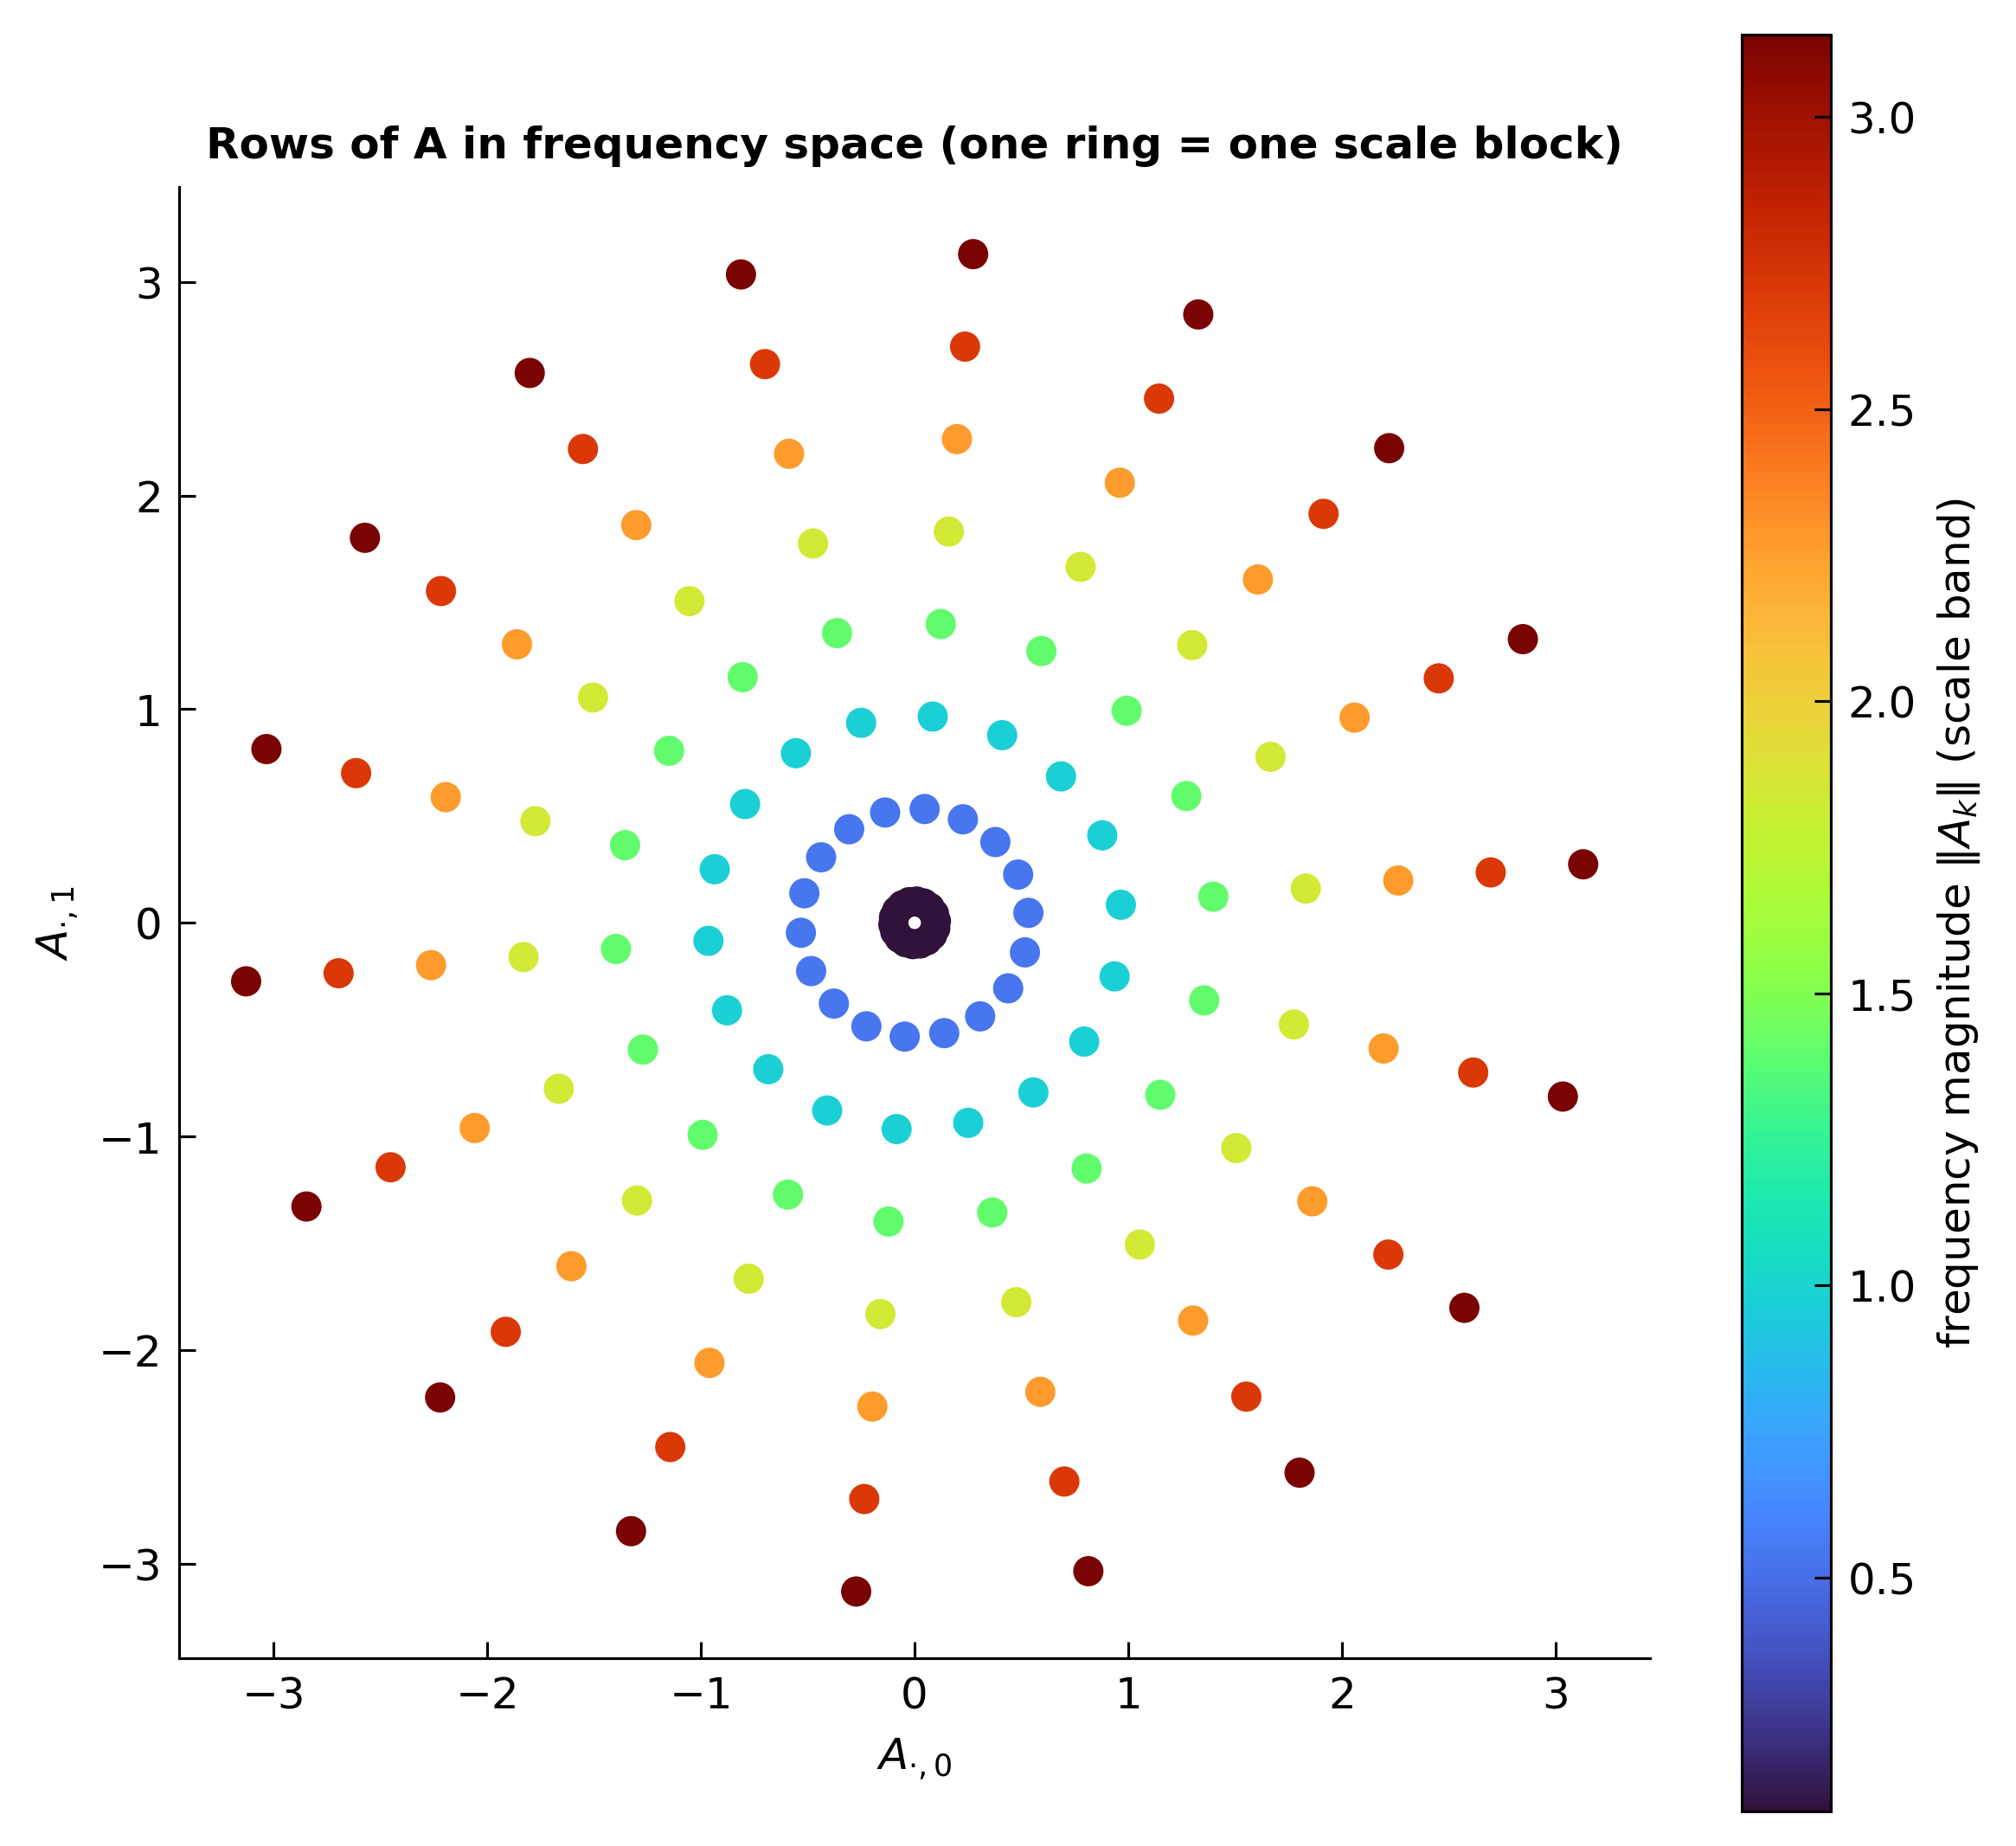

In [4]:
def row_scale_bands(ssp_space):
    '''Assign every positive-frequency row of the phase matrix to a scale band by its
    frequency magnitude ||A_row||. All rows of a grid at one scale share a magnitude
    (rotations only turn them), so this grouping does not depend on row ordering.
    Returns (scale_index_per_row, sorted unique magnitudes).'''
    d = ssp_space.num_grids * ssp_space.grid_basis_dim
    norms = np.linalg.norm(ssp_space.phase_matrix[1:d + 1], axis=1)
    mags = np.unique(norms.round(6))                          # one magnitude per scale band
    scale_of_row = np.argmin(np.abs(norms[:, None] - mags[None, :]), axis=1)
    return scale_of_row, mags

scale_of_row, scale_mags = row_scale_bands(ssp_space)    # (d_pos,) band index per positive freq
assert len(scale_mags) == n_scales
print(f'recovered {len(scale_mags)} scale bands; magnitudes = {np.round(scale_mags, 3)}')

Apos = A[1:d_pos + 1]                                     # positive-frequency rows only
plt.figure(figsize=(6, 5.5))
sc = plt.scatter(Apos[:, 0], Apos[:, 1], c=scale_mags[scale_of_row], cmap='turbo', s=28)
plt.colorbar(sc, label=r'frequency magnitude $\|A_k\|$ (scale band)')
plt.gca().set_aspect('equal')
plt.xlabel(r'$A_{\cdot,0}$'); plt.ylabel(r'$A_{\cdot,1}$')
plt.title('Rows of A in frequency space (one ring = one scale block)')
plt.tight_layout()

## 4. Block modulation of the encoding

We modulate the encoding with a real, per-frequency gain $g$. We only *choose* one gain **per
scale band** (`n_scales` numbers); `build_gain` expands that into a full length-`ssp_dim` vector by

1. assigning each positive-frequency row the gain of its scale block,
2. mirroring those gains onto the conjugate (negative) frequencies so $\tilde\phi$ stays **real**,
3. leaving the DC term at 1.

`encode_modulated` then applies $g$ in the Fourier domain. Both helpers are vectorized: pass a
`(n_scales,)` vector for one global gain, or a `(n_samples, n_scales)` array for a **different gain
at every location** (used for the non-stationary kernel below).

In [5]:
def build_gain(ssp_space, scale_gains, scale_of_row):
    '''Expand per-scale gains -> full conjugate-symmetric length-ssp_dim gain vector(s).

    scale_gains : (n_scales,) or (n_samples, n_scales)
    returns     : (n_samples, ssp_dim)
    '''
    scale_gains = np.atleast_2d(scale_gains)             # (m, n_scales)
    d = len(scale_of_row)
    n = ssp_space.ssp_dim
    g = np.ones((scale_gains.shape[0], n))
    g_pos = scale_gains[:, scale_of_row]                 # (m, d)  gain of each positive freq
    g[:, 1:d + 1] = g_pos
    g[:, d + 1:]  = g_pos[:, ::-1]                        # mirror onto conjugate freqs
    return g

def encode_modulated(ssp_space, x, gain):
    '''Hex-SSP encoding with a per-frequency gain applied in the Fourier domain.

    gain : (ssp_dim,) applied to every sample, or (n_samples, ssp_dim) one per sample.
    '''
    x = np.atleast_2d(x)
    ls_mat = np.diag(1.0 / ssp_space.length_scale.flatten())
    coeff = np.exp(1j * ssp_space.phase_matrix @ (x @ ls_mat).T)   # (ssp_dim, n_samples)
    coeff = coeff * np.atleast_2d(gain).T                          # broadcast gain
    return np.fft.ifft(coeff, axis=0).real.T

# sanity check: gain of all ones reproduces the ordinary encoding
_g1 = build_gain(ssp_space, np.ones(n_scales), scale_of_row)
assert np.allclose(encode_modulated(ssp_space, grid_pts[:50], _g1),
                   ssp_space.encode(grid_pts[:50]))
print('OK: unit gain reproduces ssp_space.encode')

OK: unit gain reproduces ssp_space.encode


## 5. Static block modulation reshapes the (stationary) kernel

A single, location-independent gain gives a different but still **stationary** kernel. Keeping only
**coarse** scales (a low-pass block gain) gives a wide, smooth bump; keeping only **fine** scales (a
high-pass block gain) gives a narrow, oscillatory kernel. This is the hexagonal-2D analogue of the
band-masking demo in the 1D notebook.

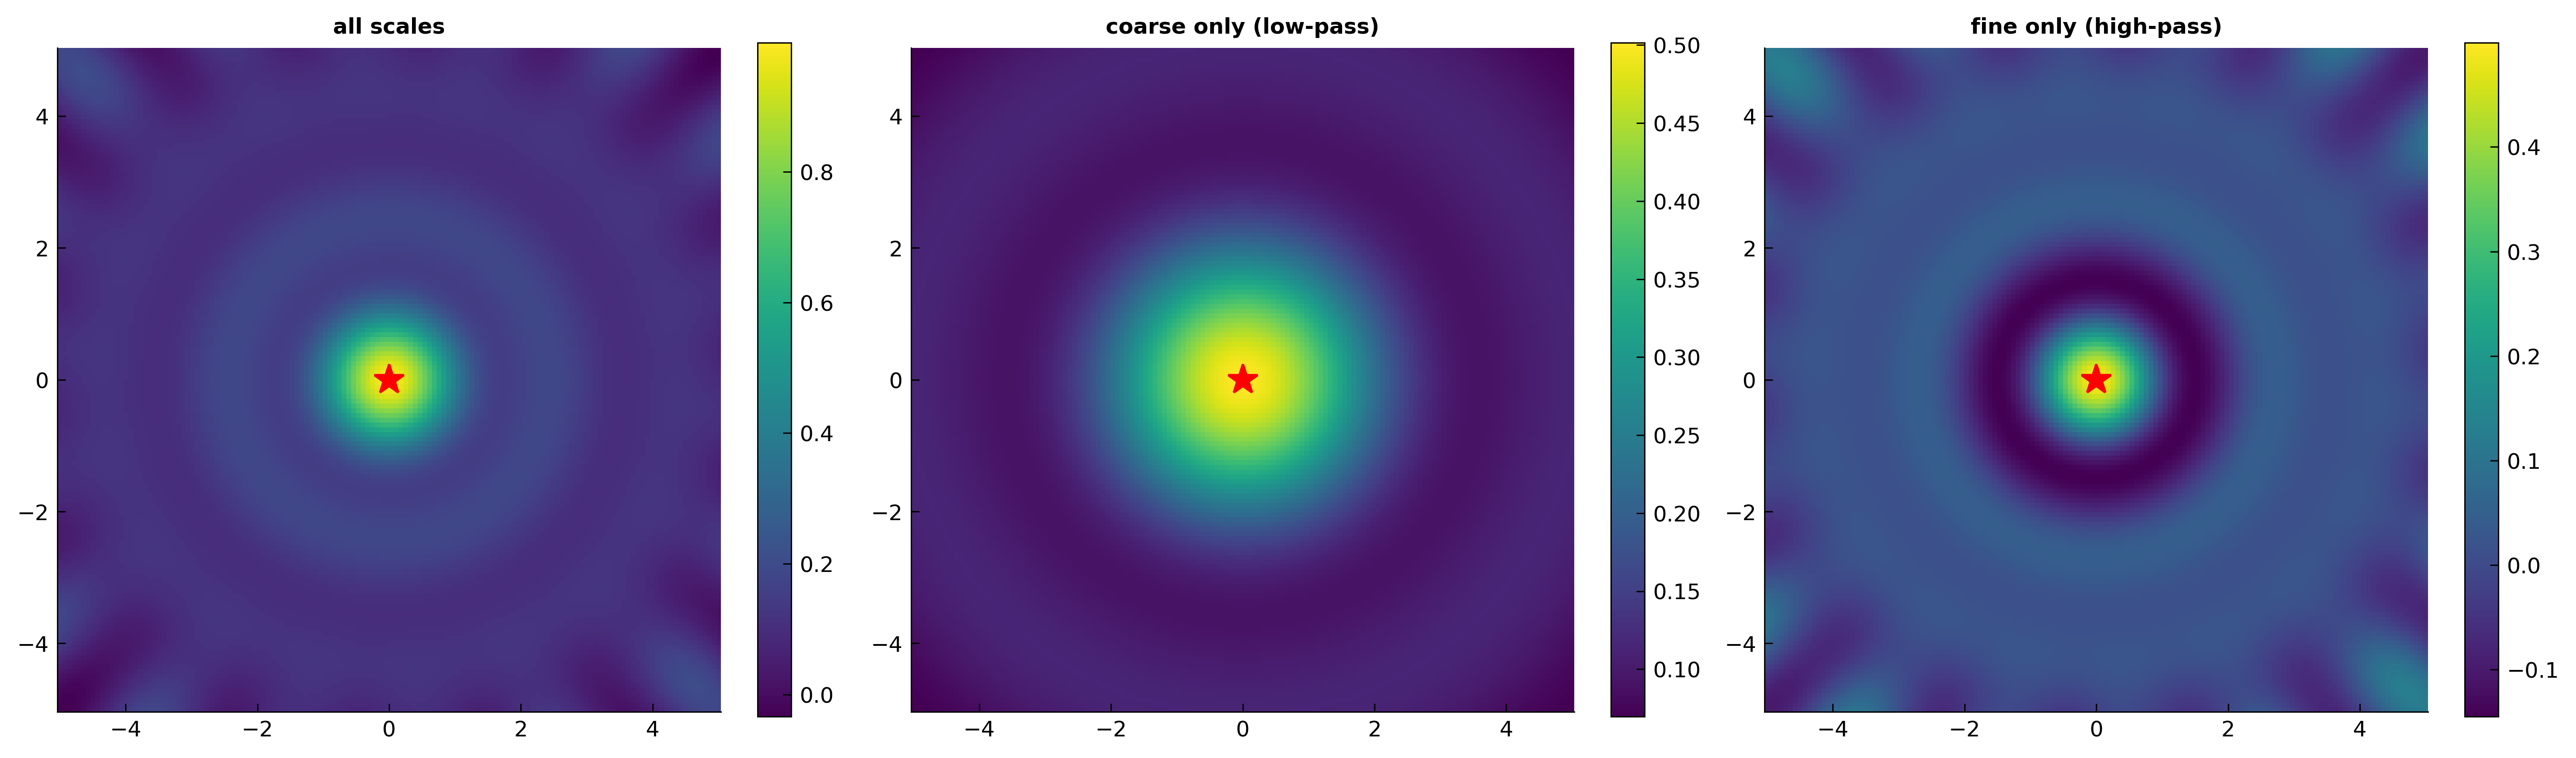

In [6]:
profiles = {
    'all scales':            np.ones(n_scales),
    'coarse only (low-pass)': (np.arange(n_scales) < n_scales // 2).astype(float),
    'fine only (high-pass)':  (np.arange(n_scales) >= n_scales // 2).astype(float),
}

query = np.array([[0.0, 0.0]])
fig, axes = plt.subplots(1, len(profiles), figsize=(15, 4.3))
for ax, (name, scale_gain) in zip(axes, profiles.items()):
    g = build_gain(ssp_space, scale_gain, scale_of_row)
    grid_mod  = encode_modulated(ssp_space, grid_pts, g)
    query_mod = encode_modulated(ssp_space, query, g)
    sims = grid_mod @ query_mod.T
    im = ax.pcolormesh(X, Y, sims.reshape(X.shape), shading='auto', cmap='viridis')
    ax.plot(0, 0, 'r*', ms=13); ax.set_aspect('equal'); ax.set_title(name)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

## 6. Location-dependent block modulation → a non-stationary kernel

Now let the block gains depend on **where** we are. We define a scalar **sharpness field**
$\sigma(x)\in[0,1]$ that is high in a region of interest and low elsewhere, and we **gate the fine
scale blocks** by it: coarse scales are always on, fine scales are active only where $\sigma$ is
high.

The resulting kernel is genuinely non-stationary: near the sharp region the fine scales survive and
the kernel is **narrow**; in the flat region only coarse scales remain and the kernel is **wide** —
even though it is built from the same encoding matrix $A$.

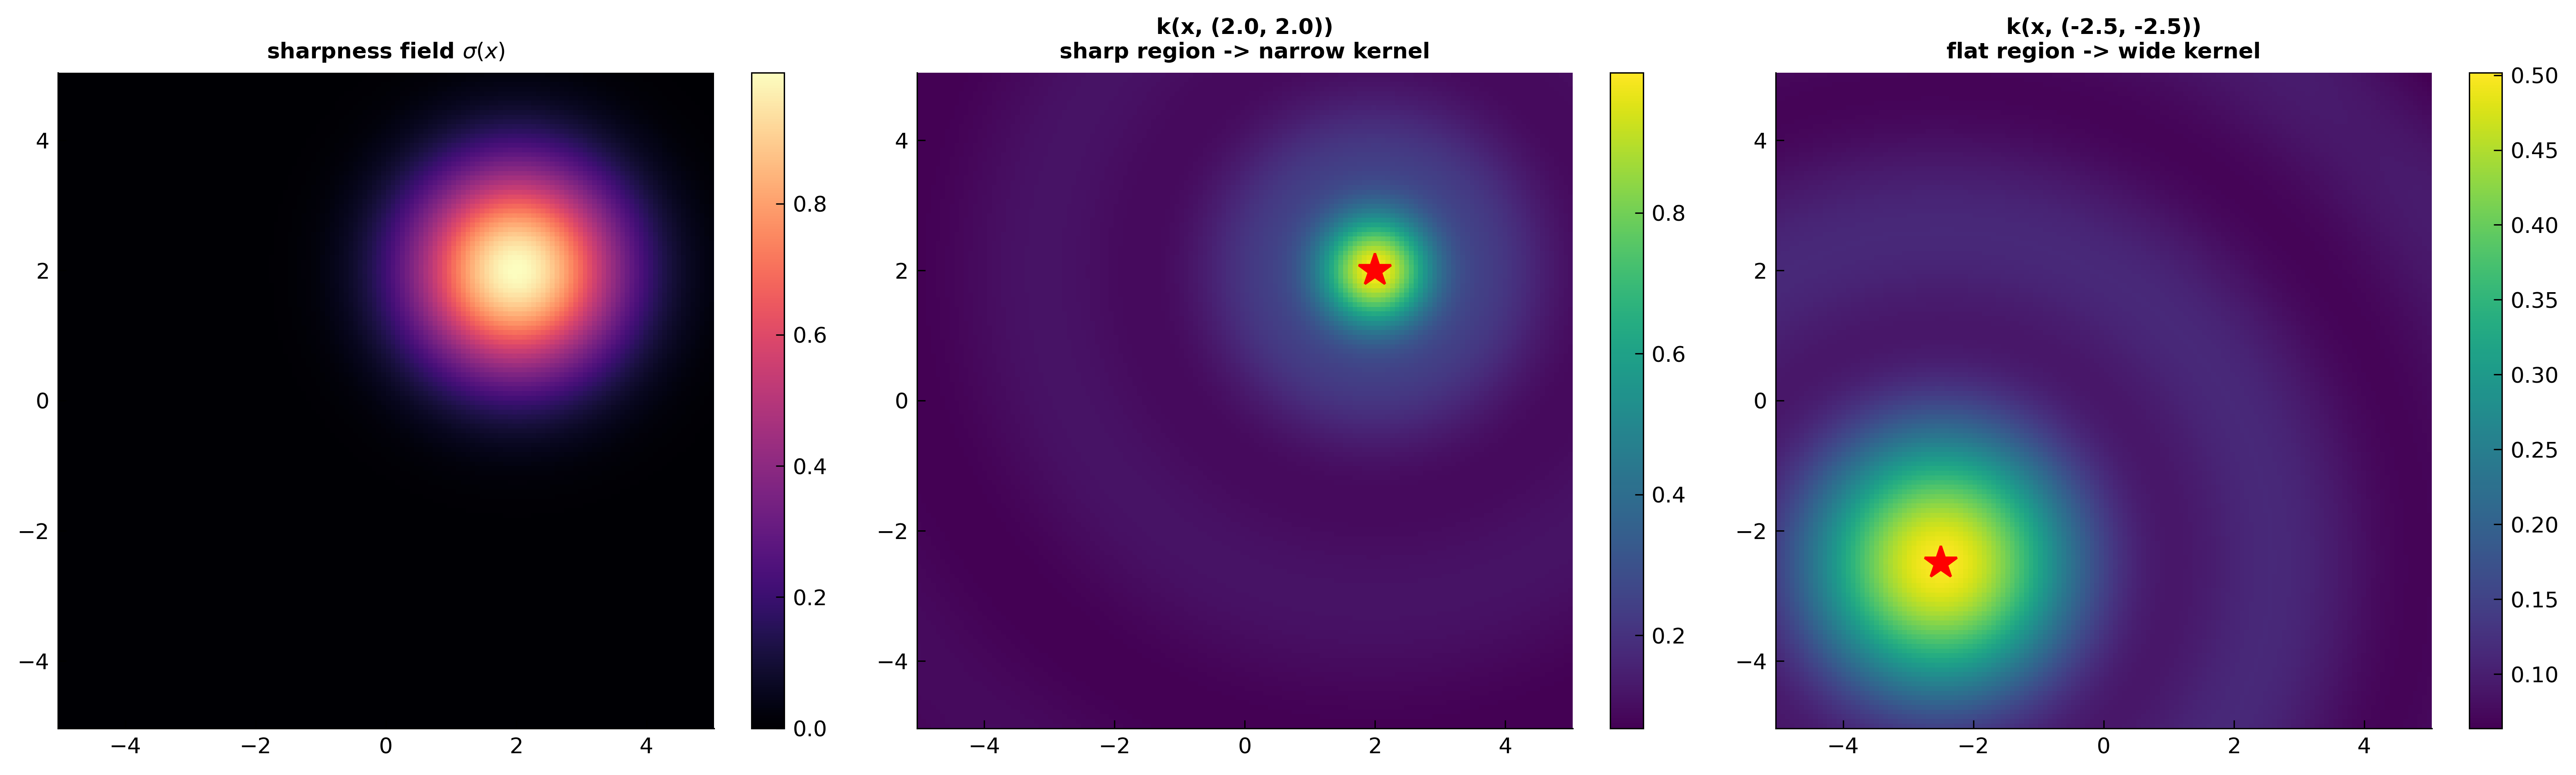

In [7]:
center = np.array([2.0, 2.0])

def sharpness_field(pts, center=center, radius=1.6):
    '''Scalar field in [0, 1]: ~1 near `center`, ->0 far away.'''
    r = np.linalg.norm(np.atleast_2d(pts) - center, axis=1)
    return np.exp(-(r / radius) ** 2)

coarse_cut = n_scales // 2                     # scales >= coarse_cut are the 'fine' blocks
is_fine = np.arange(n_scales) >= coarse_cut

def location_scale_gains(pts):
    '''Per-point per-scale gains: coarse blocks always on, fine blocks gated by sharpness.'''
    pts = np.atleast_2d(pts)
    sg = np.ones((pts.shape[0], n_scales))
    sg[:, is_fine] = sharpness_field(pts)[:, None]
    return sg

# non-stationary features over the whole grid
grid_gain = build_gain(ssp_space, location_scale_gains(grid_pts), scale_of_row)
grid_ns   = encode_modulated(ssp_space, grid_pts, grid_gain)

# two anchors: one inside the sharp region, one in the flat region
anchors = np.array([[2.0, 2.0], [-2.5, -2.5]])
anchor_gain = build_gain(ssp_space, location_scale_gains(anchors), scale_of_row)
anchor_ns   = encode_modulated(ssp_space, anchors, anchor_gain)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
im0 = axes[0].pcolormesh(X, Y, sharpness_field(grid_pts).reshape(X.shape),
                         shading='auto', cmap='magma')
axes[0].set_title(r'sharpness field $\sigma(x)$'); axes[0].set_aspect('equal')
fig.colorbar(im0, ax=axes[0], fraction=0.046)

for ax, a, a_ssp in zip(axes[1:], anchors, anchor_ns):
    sims = grid_ns @ a_ssp
    im = ax.pcolormesh(X, Y, sims.reshape(X.shape), shading='auto', cmap='viridis')
    ax.plot(a[0], a[1], 'r*', ms=14); ax.set_aspect('equal')
    region = 'sharp region -> narrow kernel' if sharpness_field(a[None])[0] > 0.5 \
             else 'flat region -> wide kernel'
    ax.set_title(f'k(x, {tuple(a)})\n{region}')
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

## 7. Does it help non-linear regression?

Finally we regress against a 2D function whose complexity varies over space: a sharp, oscillatory
bump near $(2,2)$ on top of a slow global trend that is otherwise flat. We compare linear regression
in two feature spaces of the **same dimension**:

- **stationary** Hex-SSP features `ssp_space.encode(x)`,
- **block-modulated** non-stationary features (fine scales gated by the same sharpness field).

The modulated features concentrate their fine-scale capacity where the function is actually sharp,
so they fit the target with substantially lower test error.

In [8]:
from sklearn.linear_model import Ridge

rng = np.random.default_rng(1)

def target(pts):
    pts = np.atleast_2d(pts)
    r2 = np.sum((pts - center) ** 2, axis=1)
    sharp = -np.cos(3 * (pts[:, 0] - 2)) * np.cos(3 * (pts[:, 1] - 2)) * np.exp(-r2 / 1.5)
    trend = 0.1 * np.sin(0.5 * pts[:, 0])
    return sharp + trend

train_x = rng.uniform(-5, 5, size=(400, 2)); train_y = target(train_x)
test_x  = rng.uniform(-5, 5, size=(3000, 2)); test_y = target(test_x)

feat = {
    'stationary': lambda p: ssp_space.encode(p),
    'block-modulated (non-stationary)':
        lambda p: encode_modulated(ssp_space, p,
                                   build_gain(ssp_space, location_scale_gains(p), scale_of_row)),
}

alpha = 1e-2          # Hex-SSP features are highly collinear; ridge + the stable SVD solver
preds = {}
for name, phi in feat.items():
    reg = Ridge(alpha=alpha, fit_intercept=False, solver='svd').fit(phi(train_x), train_y)
    preds[name] = reg.predict(phi(grid_pts))
    mse = np.mean((reg.predict(phi(test_x)) - test_y) ** 2)
    print(f'{name:35s}  test MSE = {mse:.5f}')

stationary                           test MSE = 0.00633


block-modulated (non-stationary)     test MSE = 0.00332


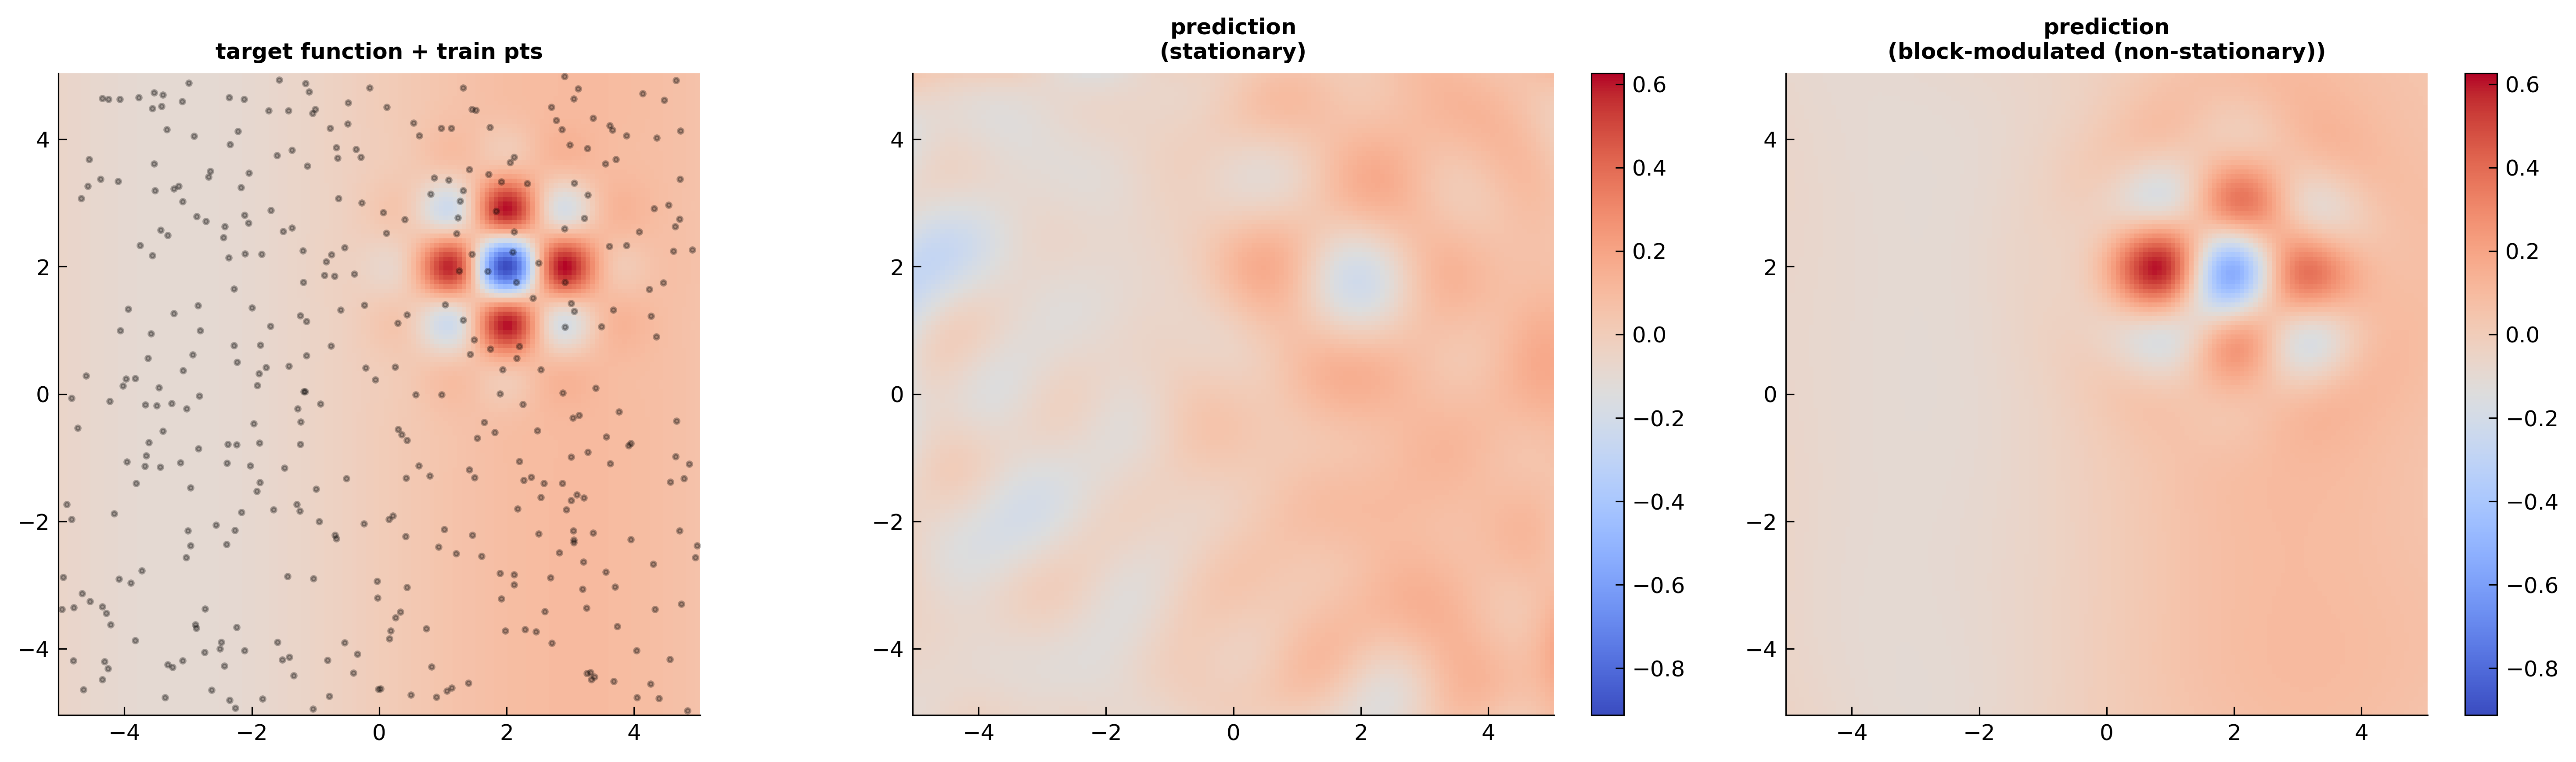

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
vmin, vmax = target(grid_pts).min(), target(grid_pts).max()

axes[0].pcolormesh(X, Y, target(grid_pts).reshape(X.shape),
                   shading='auto', cmap='coolwarm', vmin=vmin, vmax=vmax)
axes[0].scatter(train_x[:, 0], train_x[:, 1], s=4, c='k', alpha=0.3)
axes[0].set_title('target function + train pts'); axes[0].set_aspect('equal')

for ax, (name, pred) in zip(axes[1:], preds.items()):
    im = ax.pcolormesh(X, Y, pred.reshape(X.shape), shading='auto',
                       cmap='coolwarm', vmin=vmin, vmax=vmax)
    ax.set_title(f'prediction\n({name})'); ax.set_aspect('equal')
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()

## Takeaways

- Hexagonal SSPs give a phase matrix $A$ with a natural **block structure**: rows are grouped into
  grids by **scale** (spatial-frequency band) and rotation.
- Applying a **per-scale (block-constant) gain** in the Fourier domain reshapes the kernel while
  keeping the encoding real — coarse blocks control the broad shape, fine blocks the detail.
- Making those block gains **location-dependent** turns the stationary Hex-SSP kernel into a
  **non-stationary** one: sharp where fine scales are switched on, smooth where they are switched
  off, all from the same matrix $A$.
- Spatially allocating fine-scale capacity this way improves regression on functions whose
  complexity varies over the domain.

In a neural implementation the per-scale gains are exactly a **neuromodulatory** signal on the grid
cells of each scale; here we set them by hand, but they could equally be predicted from the current
location or learned.